In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import os

from models import FluxNet
from models import compute_divergence_field

device = "cuda" if torch.cuda.is_available() else "cpu"

# RETRAIN = False
RETRAIN = True

N_ENSEMBLE = 1

# Load data

In [2]:
data = torch.load("data/flux_tensor.pt", weights_only = False)
print(data.shape)

### Make torch.dataset ###
# takes two separate tensors as input
dataset = TensorDataset(data[:, :2], data[:, 2:])

# Inspect
# Shape of (first) X sample
print(dataset[0][0].shape)
# Shape of (first) Y sample
print(dataset[0][1].shape)

### Create DataLoader ###
all_loader = DataLoader(dataset, batch_size = 1024, shuffle = True)

torch.Size([237475, 4])
torch.Size([2])
torch.Size([2])


# Train single model

In [3]:
# ----- Training loop -----
if RETRAIN:
    
    model = FluxNet().to(device)
    # 5e-3 was a bit jittery
    optim = torch.optim.AdamW(model.parameters(), lr = 1e-3, weight_decay = 1e-7)
    loss_function = nn.MSELoss()

    epochs = 18
    # epochs = 10

    losses = []

    for ep in range(1, epochs + 1):
        # ------------------ TRAIN ------------------
        model.train()
        train_loss_sum = 0.0
        
        # NOTE: Train on ALL data (no split)
        for i, (X_batch, Y_batch) in enumerate(all_loader):

            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            optim.zero_grad(set_to_none = True)

            Y_hat = model(X_batch)

            loss = loss_function(Y_hat, Y_batch)
            
            loss.backward()
            optim.step()

            train_loss_sum += loss.item() * X_batch.size(0)

        epoch_avg_train_loss = train_loss_sum / len(all_loader.dataset)

        # store for plotting later
        losses.append(epoch_avg_train_loss)

        # Print every epoch: ~ 2 min per epoch
        # ~14 min for 10 epochs on GPU
        print(f"[epoch {ep:03d}] train_loss = {epoch_avg_train_loss:.6f}")

    # ------------------ SAVE ------------------
    torch.save(model.state_dict(), "trained_fluxnet/fluxnet_full_model.pth")
    pd.DataFrame({'train_loss': losses}).to_csv("trained_fluxnet/fluxnet_loss.csv", index = False)

[epoch 001] train_loss = 0.042620
[epoch 002] train_loss = 0.003951
[epoch 003] train_loss = 0.003679
[epoch 004] train_loss = 0.003615
[epoch 005] train_loss = 0.003531
[epoch 006] train_loss = 0.003403
[epoch 007] train_loss = 0.003406
[epoch 008] train_loss = 0.003358
[epoch 009] train_loss = 0.002812
[epoch 010] train_loss = 0.002363
[epoch 011] train_loss = 0.002154
[epoch 012] train_loss = 0.001947
[epoch 013] train_loss = 0.001841
[epoch 014] train_loss = 0.001715
[epoch 015] train_loss = 0.001635
[epoch 016] train_loss = 0.001581
[epoch 017] train_loss = 0.001575
[epoch 018] train_loss = 0.001543


### Note: about 5 minutes for 18 iterations

# Train all ensemble members

In [ ]:
# Use e because we haven't used it yet
for e in range(N_ENSEMBLE):

    print(f"Training ensemble member {e + 1} of {N_ENSEMBLE}")

    # Initialize the model for this ensemble member (weights are randomly initialized)
    model = FluxNet().to(device)
    # 5e-3 was a bit jittery
    optim = torch.optim.AdamW(model.parameters(), lr = 1e-3, weight_decay = 1e-7)
    loss_function = nn.MSELoss()

    epochs = 12
    # epochs = 10

    losses = []

    for ep in range(1, epochs + 1):
        # ------------------ TRAIN ------------------
        model.train()
        train_loss_sum = 0.0
        
        # NOTE: Train on ALL data (no split)
        for i, (X_batch, Y_batch) in enumerate(all_loader):

            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            optim.zero_grad(set_to_none = True)

            Y_hat = model(X_batch)

            loss = loss_function(Y_hat, Y_batch)
            
            loss.backward()
            optim.step()

            train_loss_sum += loss.item() * X_batch.size(0)

        epoch_avg_train_loss = train_loss_sum / len(all_loader.dataset)

        # store for plotting later
        losses.append(epoch_avg_train_loss)

        # Print every epoch: ~ 2 min per epoch
        # ~14 min for 10 epochs on GPU
        print(f"[epoch {ep:03d}] train_loss = {epoch_avg_train_loss:.6f}")

    # ------------------ SAVE ------------------
    torch.save(model.state_dict(), "fluxnet_trained_on_all_data/fluxnet_full_model_" + str(e) + ".pth")
    pd.DataFrame({'train_loss': losses}).to_csv("fluxnet_trained_on_all_data/fluxnet_loss_" + str(e) + ".csv", index = False)

Training ensemble member 1 of 8
[epoch 001] train_loss = 0.088574
[epoch 002] train_loss = 0.019548
[epoch 003] train_loss = 0.015178
[epoch 004] train_loss = 0.012958
[epoch 005] train_loss = 0.012012
[epoch 006] train_loss = 0.010784
[epoch 007] train_loss = 0.009702
[epoch 008] train_loss = 0.010730
[epoch 009] train_loss = 0.009122
[epoch 010] train_loss = 0.008599
[epoch 011] train_loss = 0.008367
[epoch 012] train_loss = 0.008015
Training ensemble member 2 of 8
[epoch 001] train_loss = 0.072501
[epoch 002] train_loss = 0.018390
[epoch 003] train_loss = 0.014595
[epoch 004] train_loss = 0.011803
[epoch 005] train_loss = 0.010832
[epoch 006] train_loss = 0.009718
[epoch 007] train_loss = 0.009134
[epoch 008] train_loss = 0.008635
[epoch 009] train_loss = 0.008219
[epoch 010] train_loss = 0.007787
[epoch 011] train_loss = 0.007677
[epoch 012] train_loss = 1354.600737
Training ensemble member 3 of 8
[epoch 001] train_loss = 0.081840
[epoch 002] train_loss = 0.021442
[epoch 003] train

trained in 2 minutes (12 epochs).

## Visualise loss convergence

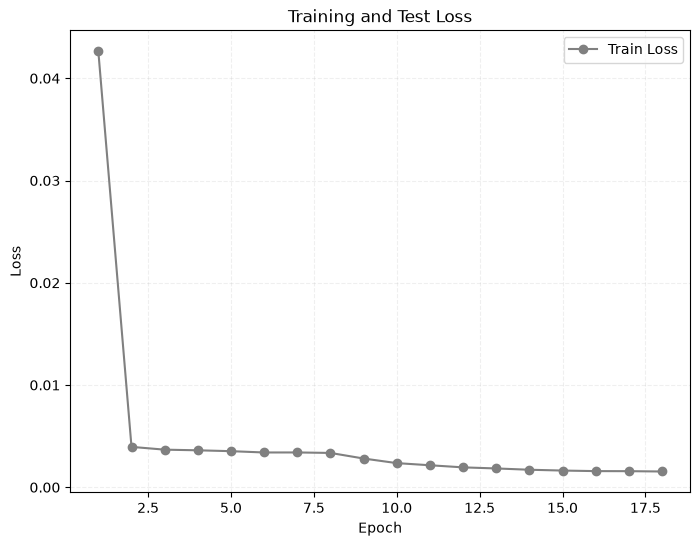

In [4]:
if RETRAIN:
    # Assume you already have train_losses and test_losses lists
    epochs = range(1, len(losses) + 1)

    plt.figure(figsize = (8, 6))
    plt.plot(epochs, losses, label = "Train Loss", marker = "o", color = "gray")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Test Loss")

    plt.legend()

    plt.grid(True, linestyle = "--", alpha = 0.2)
    #plt.ylim(0, 0.3)
    plt.show()

# Load trained model

In [5]:
# Initialise
model = FluxNet().to(device)
# Load trained weights
model.load_state_dict(torch.load("trained_fluxnet/fluxnet_full_model.pth", map_location = device))
model.eval()

FluxNet(
  (inp): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): SiLU()
  )
  (trunk): ModuleList(
    (0-5): 6 x _ResBlock(
      (lin1): Linear(in_features=256, out_features=256, bias=True)
      (lin2): Linear(in_features=256, out_features=256, bias=True)
      (act): SiLU()
    )
  )
  (head_df_psi): Linear(in_features=256, out_features=1, bias=True)
  (head_cf_phi): Linear(in_features=256, out_features=1, bias=True)
)

In [ ]:
# All data is a bit dense (and memory intensive), so we spatially subsample
def spatial_subsample(data, n_cells = 100):
    x, y = data[:, 0], data[:, 1]

    # Compute integer cell indices
    ix = torch.clamp((x * n_cells).long(), max = n_cells - 1)
    iy = torch.clamp((y * n_cells).long(), max = n_cells - 1)
    cell_ids = ix * n_cells + iy   # [N]

    # Shuffle indices to randomize
    perm = torch.randperm(data.shape[0])
    cell_ids_perm = cell_ids[perm]

    # Get inverse mapping: which unique id each entry belongs to
    unique_ids, inv = torch.unique(cell_ids_perm, return_inverse = True)

    # First index per unique id = argmin within each group
    # Build a large index tensor and take the min
    arange = torch.arange(len(cell_ids_perm), device = data.device)
    first_idx = torch.full((len(unique_ids),), len(cell_ids_perm), device = data.device)

    first_idx = first_idx.scatter_reduce(0, inv, arange, reduce = "amin", include_self = True)

    # Map back to permuted indices
    chosen = perm[first_idx]

    return data[chosen]

# 4 k e.g
subset = spatial_subsample(data, n_cells = 200)
print(subset.shape)

torch.Size([4108, 4])


In [7]:
subset_x = subset[:, :2].to(device)
subset_y = subset[:, 2:].to(device)

prediction = model(subset_x.requires_grad_(True))

div_field = compute_divergence_field(
    mean_pred = prediction, 
    x_grad = subset_x)

rmse_field = torch.sqrt(torch.mean((prediction - subset_y) ** 2, dim = 1))
me_field = torch.mean((prediction - subset_y), dim = 1)
me_field.mean()

tensor(-0.0007, grad_fn=<MeanBackward0>)

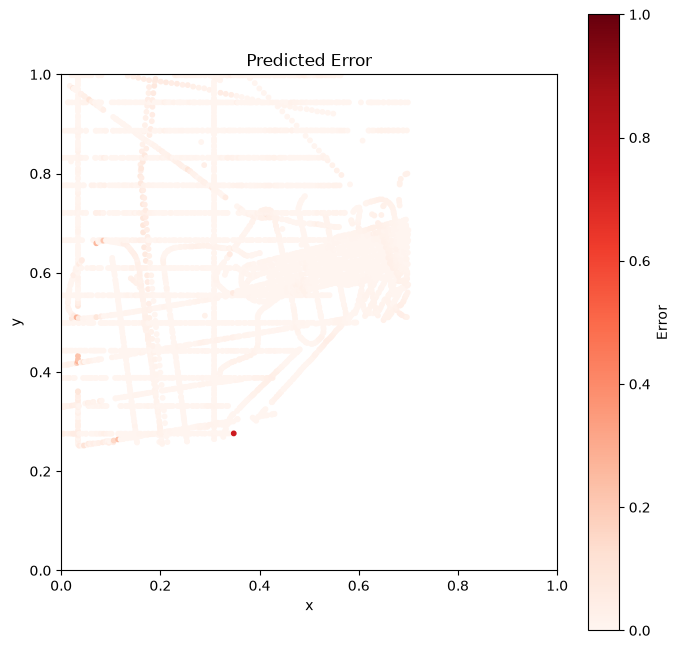

In [8]:
plt.figure(figsize = (8, 8))
plt.scatter(
    subset_x[:, 0].cpu().detach().numpy(), 
    subset_x[:, 1].cpu().detach().numpy(),
    c = me_field.cpu().detach().numpy(), 
    cmap = "Reds", 
    vmin = 0, vmax = 1,
    s = 10)
plt.colorbar(label = "Error")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Predicted Error")
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.gca().set_aspect("equal")
plt.show()

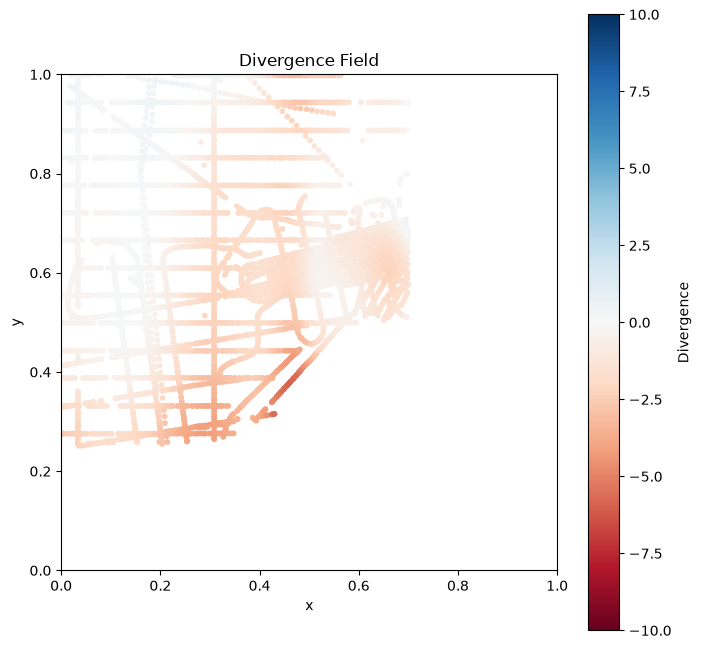

In [9]:
plt.figure(figsize = (8, 8))
plt.scatter(
    subset_x[:, 0].cpu().detach().numpy(), 
    subset_x[:, 1].cpu().detach().numpy(),
    c = div_field.cpu().detach().numpy(), 
    cmap = "RdBu", 
    vmin = -10, vmax = 10,
    s = 10)
plt.colorbar(label = "Divergence")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divergence Field")
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.gca().set_aspect("equal")
plt.show()

# Inference

In [126]:
XY_long_tensor = torch.load("data/XY_long_tensor.pt")
combined_mask = torch.load("data/combined_mask.pt")
stricter_combined_mask = torch.load("data/stricter_combined_mask.pt")

In [12]:
from regions import ROSS_ISLAND_BOUNDS

x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

In [13]:
path_to_phase_based_ice_vel = "/Users/kim.bente/DATA/ice_velocity/NSIDC-0484_2-20261004_220442/antarctica_ice_velocity_450m_v2.nc"

ice_vel_phase = xr.open_dataset(path_to_phase_based_ice_vel)
# print(ice_vel_phase)  # shows variables, dimensions and coordinates

# Subset for Ross Island region
ice_vel_phase_ross_island = ice_vel_phase.sel(
    x = slice(x_min, x_max),
    y = slice(y_max, y_min) # Note: y_max and y_min are reversed because y decreases southward in polar stereographic coordinates
)

In [62]:
# X: 445 columns, Y: 400 rows
X_t, Y_t = xr.broadcast(ice_vel_phase_ross_island.x, ice_vel_phase_ross_island.y)
# broadcast is X Y ordered
X = X_t.T
Y = Y_t.T

X_long = X.values.flatten()
Y_long = Y.values.flatten()

# Normalise
X_long_norm = (X_long - x_min) / (x_max - x_min)
Y_long_norm = (Y_long - y_min) / (y_max - y_min)
# to exclude nas
VX_long = ice_vel_phase_ross_island.VX.values.flatten()

XY_long_tensor = torch.cat((
    torch.tensor(X_long_norm).unsqueeze(1), 
    torch.tensor(Y_long_norm).unsqueeze(1),
    torch.tensor(VX_long).unsqueeze(1),
    ), dim = 1)

print(XY_long_tensor.shape)

# square valids mask
valid_mask = ~ torch.isnan(torch.tensor(ice_vel_phase_ross_island.VX.values))
below_threshold_mask = ~(torch.tensor(X.values) < 300_000)
combined_mask = valid_mask & below_threshold_mask

# remove column
XY_long_tensor = XY_long_tensor[:, :2]

print(XY_long_tensor.shape)

torch.Size([178000, 3])
torch.Size([178000, 2])


# Inference

In [77]:
# breaks with 100_000 batch size
batch_size = 10_000

# Move model to device
model = model.to(device)
# Put in eval mode
model.eval()

# Move data to device (not too big for memory)
XY_long_tensor = XY_long_tensor.to(device).to(torch.float32)
    
# Total length
N = XY_long_tensor.shape[0]

# container for divergence batches
div_container = torch.empty((N,), dtype = torch.float32, device = "cpu")
 
for i in range(0, N, batch_size):

    # Define end index
    j = min(i + batch_size, N)

    print(f"Processing batch {i} to {j}...")

    # Subset batch
    XY_batch = XY_long_tensor[i : j , :]

    # Enable gradients
    XY_batch = XY_batch.requires_grad_(True)

    flux_predictions_batch = model(XY_batch)


    div_batch = compute_divergence_field(
        mean_pred = flux_predictions_batch, 
        x_grad = XY_batch)
    
    # For now only return divergence
    div_container[i:j] = div_batch.detach().cpu() 

    del div_batch
    del flux_predictions_batch
    torch.cuda.empty_cache()

    # for testing
    # if j == 100_000:
    #    break

Processing batch 0 to 10000...
Processing batch 10000 to 20000...
Processing batch 20000 to 30000...
Processing batch 30000 to 40000...
Processing batch 40000 to 50000...
Processing batch 50000 to 60000...
Processing batch 60000 to 70000...
Processing batch 70000 to 80000...
Processing batch 80000 to 90000...
Processing batch 90000 to 100000...
Processing batch 100000 to 110000...
Processing batch 110000 to 120000...
Processing batch 120000 to 130000...
Processing batch 130000 to 140000...
Processing batch 140000 to 144000...


## Reshape div estimates long -> square

In [78]:
# Take the shapes from the mask directly
div_container_square = div_container.unsqueeze(1).reshape(combined_mask.shape[0], combined_mask.shape[1])
print("Divergence field shape:", div_container_square.shape)

Divergence field shape: torch.Size([360, 400])


## Mask out invalid grid cells

In [128]:
# 1 is valid, 0 not
# Replace invalid cells with nana
div_container_square_masked = div_container_square.masked_fill(stricter_combined_mask != 1, float("nan"))

# Reshape long input

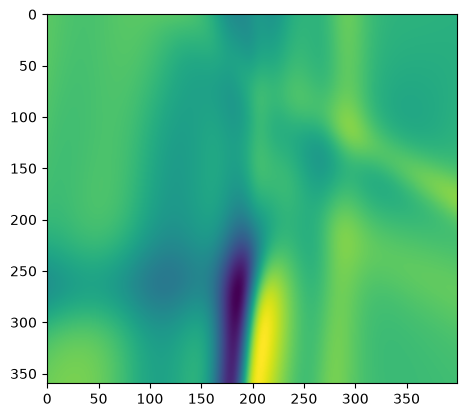

In [103]:
plt.imshow(div_container_square.cpu().detach().numpy())

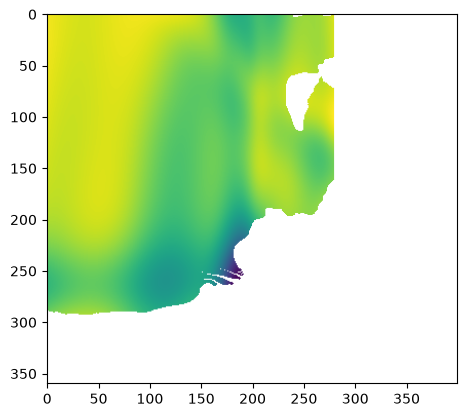

In [114]:
plt.imshow(div_container_square_masked.cpu().detach().numpy())

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_25329/1525414474.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(XY_long_tensor[:, 0].reshape(combined_mask.shape)).cpu().detach().numpy(),
/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_25329/1525414474.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(XY_long_tensor[:, 1].reshape(combined_mask.shape)).cpu().detach().numpy(),


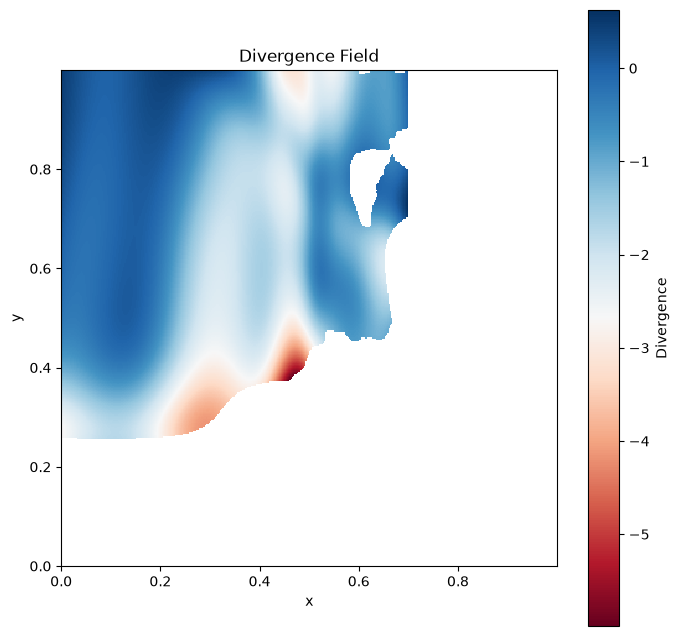

In [127]:
plt.figure(figsize = (8, 8))
plt.pcolormesh(
    # NOTE: 2D inputs
    # NOTE: Take original coords
    torch.tensor(XY_long_tensor[:, 0].reshape(combined_mask.shape)).cpu().detach().numpy(), 
    torch.tensor(XY_long_tensor[:, 1].reshape(combined_mask.shape)).cpu().detach().numpy(),
    div_container_square_masked.cpu().detach().numpy(), 
    cmap = "RdBu", 
    # equivalent to a -3, 3 mapping
    #vmax = 0.1, 
    #vmin = -0.1
)
plt.colorbar(label = "Divergence")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divergence Field")
plt.gca().set_aspect("equal")
plt.show()

# Convert units back to physical units

- **dxy = 200_000** because the normalised range [0, 1] presents [0, 200_000 m] (200 km range) in real life.
- **flux_scale = 100_000** because we devided fluxes by 100_000 to acheve ~ 1 std i.e. var of flux in both directions.
- To rescale the div_field to physical units we do **div_phys = div_field * flux_scale / dxy**
- This simplifies to **dividing by 2** to get **m / year** units.

Prior:
- **dxy = 1_000_000** because the normalised range [0, 1] presents [0, 1_000_000 m] (1000 km range) in real life.
- **flux_scale = 100_000** because we devided fluxes by 100_000 to acheve ~ 1 std i.e. var of flux in both directions.
    - The mean ice thickness of 420 meters * 438 mean ice speed yields ice flux of 183_960 for example.
- To rescale the div_field to physical units we do **div_phys = div_field * flux_scale / dxy**
- This simplifies to **dividing by 10** to get **m / year** units.

# Visualise with MODIS

In [90]:
X_ps = torch.tensor(XY_long_tensor[:, 0].reshape(combined_mask.shape)).cpu().detach().numpy() * (x_max - x_min) + x_min
Y_ps = torch.tensor(XY_long_tensor[:, 1].reshape(combined_mask.shape)).cpu().detach().numpy() * (y_max - y_min) + y_min

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_25329/3967556620.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_ps = torch.tensor(XY_long_tensor[:, 0].reshape(combined_mask.shape)).cpu().detach().numpy() * (x_max - x_min) + x_min
/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_25329/3967556620.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Y_ps = torch.tensor(XY_long_tensor[:, 1].reshape(combined_mask.shape)).cpu().detach().numpy() * (y_max - y_min) + y_min


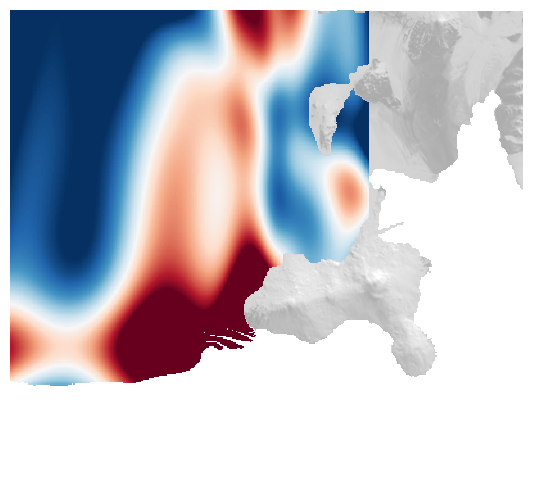

In [99]:
vis_again = True

# Only rerun if needed
if vis_again :

    # Load MODIS data
    modis_ross = torch.load("/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt", weights_only = False)

    fig, ax = plt.subplots(figsize = (8, 6))

    # 1) MODIS as background (draw first)
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.7,
        zorder = 0,
    )

    # 2) SMB on top (draw second)
    pcm = ax.pcolormesh(
        # NOTE: 2D inputs
        # NOTE: Take original coords
        X_ps,
        Y_ps,
        div_container_square_masked.cpu().detach().numpy(), 
        vmin = -3,
        vmax = 0,
        cmap = "RdBu",
        shading = "auto",
        alpha = 1.0,
        zorder = 1,
    )

    ax.set_aspect("equal")
    ax.set_axis_off()

    # crop
    ax.set_ylim(y_min, y_max)
    ax.set_xlim(x_min, x_max)

    fig.savefig("figures/fluxnet_div_ross.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
    plt.show()

# Match color scale

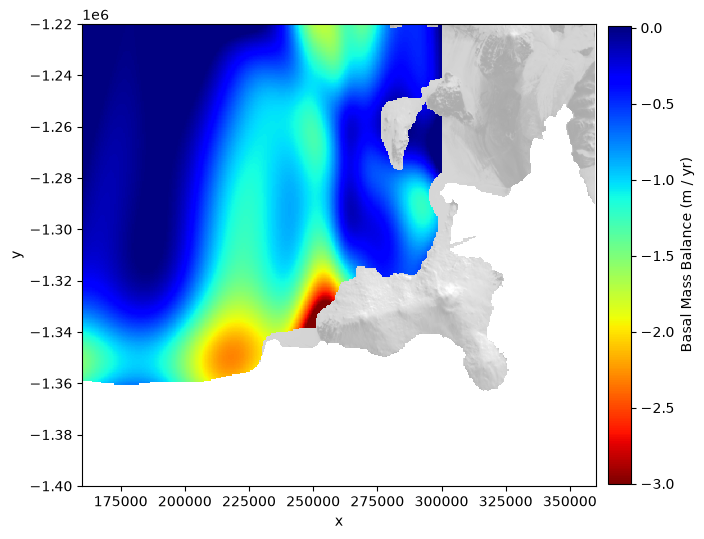

In [129]:
vis_again = True

# Only rerun if needed
if vis_again :

    # Load MODIS data
    modis_ross = torch.load("/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt", weights_only = False)

    fig, ax = plt.subplots(figsize = (8, 6))

    # 1) MODIS as background (draw first)
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.7,
        zorder = 0,
    )

    # 2) SMB on top (draw second)
    pcm = ax.pcolormesh(
        # NOTE: 2D inputs
        # NOTE: Take original coords
        X_ps,
        Y_ps,
        div_container_square_masked.cpu().detach().numpy() / 1.8, 
        vmin = -3,
        vmax = 0.01,
        cmap = "jet_r",
        shading = "auto",
        alpha = 1.0,
        zorder = 1,
    )

    ax.set_aspect("equal")
    # ax.set_axis_off()

    # crop
    ax.set_ylim(y_min, y_max)
    ax.set_xlim(x_min, x_max)

    cbar = fig.colorbar(pcm, ax = ax, shrink = 0.99, pad = 0.02)
    cbar.set_label("Basal Mass Balance (m / yr)")
    plt.xlabel("x")
    plt.ylabel("y")

    fig.savefig("figures/fluxnet_div_ross.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
    plt.show()

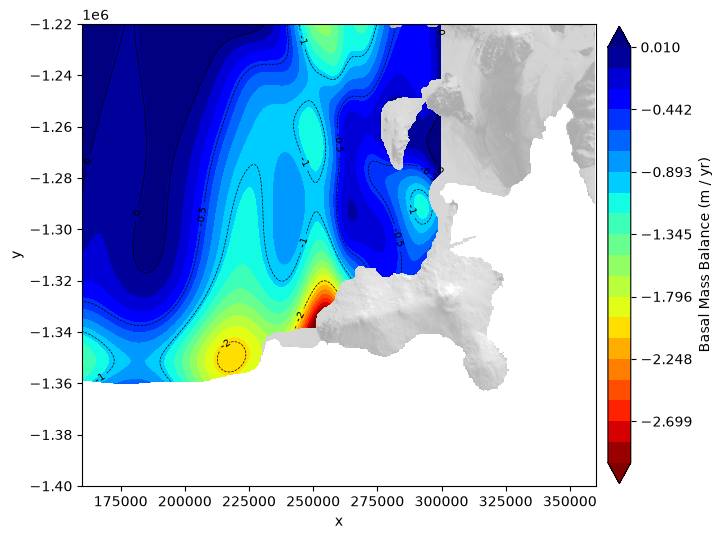

In [130]:
import numpy as np
import torch
import matplotlib.pyplot as plt

vis_again = True

# Only rerun if needed
if vis_again:

    # Load MODIS data
    modis_ross = torch.load(
        "/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt",
        weights_only = False,
    )

    # Data to plot (converted to physical units; NaNs are left blank)
    data = div_container_square_masked.cpu().detach().numpy() / 2.0

    # Contour levels: 20 bands between -3 and 0.01
    levels = np.linspace(-3, 0.01, 21)

    fig, ax = plt.subplots(figsize = (8, 6))

    # 1) MODIS as background (draw first)
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1],
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000,
        vmax = 30_000,
        # as less saturated background
        alpha = 0.7,
        zorder = 0,
    )

    # 2) Filled contours on top (draw second)
    pcm = ax.contourf(
        # NOTE: 2D inputs, original coords
        X_ps,
        Y_ps,
        data,
        levels = levels,
        cmap = "jet_r",
        extend = "both",   # colour values outside [-3, 0.01] instead of leaving them blank
        alpha = 1.0,
        zorder = 1,
    )

    # 3) Optional: thin contour lines with labels
    cs = ax.contour(
        X_ps,
        Y_ps,
        data,
        levels = [-2, -1, -0.5, 0],
        colors = "k",
        linewidths = 0.5,
        zorder = 2,
    )
    ax.clabel(cs, fmt = "%g", fontsize = 7)

    ax.set_aspect("equal")
    # ax.set_axis_off()

    # crop
    ax.set_ylim(y_min, y_max)
    ax.set_xlim(x_min, x_max)

    cbar = fig.colorbar(pcm, ax = ax, shrink = 0.99, pad = 0.02)
    cbar.set_label("Basal Mass Balance (m / yr)")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    fig.savefig("figures/fluxnet_div_ross.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
    plt.show()

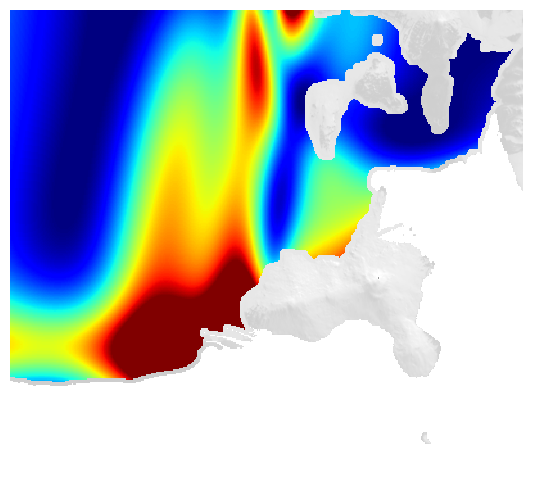

In [ ]:
vis_again = True

# Only rerun if needed
if vis_again :

    # Load MODIS data
    modis_ross = torch.load("data/modis/moa125_2014_hp1_v01_ross_with_grid_no_ocean.pt", weights_only = False)

    fig, ax = plt.subplots(figsize = (8, 6))

    # 1) MODIS as background (draw first)
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

    # 2) SMB on top (draw second)
    pcm = ax.pcolormesh(
        # NOTE: 2D inputs
        # NOTE: Take original coords
        torch.tensor(X.values).cpu().detach().numpy(), 
        torch.tensor(Y.values).cpu().detach().numpy(),
        div_square.cpu().detach().numpy(), 
        vmin = -3,
        vmax = 0.1,
        cmap = "jet_r",
        shading = "auto",
        alpha = 1.0,
        zorder = 1,
    )

    ax.set_aspect("equal")
    ax.set_axis_off()

    # crop
    ax.set_ylim(y_min, y_max)
    ax.set_xlim(x_min, x_max)

    fig.savefig("figures/fluxnet_div_ross.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
    plt.show()

In [1]:
# Note: use colourlines as well

# Generate file / overwrite variable in existing file

In [41]:
path = "data/fluxnet_div_ross.nc"

# make field numpy and scale
# m i.e. / yr
div_np = div_square.cpu().detach().numpy() / 10.0 

# ensure (y,x) ordering on the target grid
div_da = xr.DataArray(
    div_np,
    dims = ("y", "x"),
    coords = {"x": target_grid_mask["x"], "y": target_grid_mask["y"]},
    name = "fluxnet_div",
    attrs = {
        "long_name": "Flux divergence (net) converted to metres ice-equivalent per year",
        "units": "m i.e. yr-1",
    },
).transpose("y", "x")  # no-op if already correct

if not os.path.exists(path):
    ds = div_da.to_dataset()
else:
    with xr.open_dataset(path) as _ds:
        ds = _ds.load()
    ds = ds.assign_coords(x = target_grid_mask["x"], y = target_grid_mask["y"])

ds["fluxnet_div"] = div_da

tmp = path + ".tmp"
ds.to_netcdf(tmp, mode = "w")
os.replace(tmp, path)